# Track 01 Workflow: How Much of the Preeclampsia Signal Is Just Delivery Timing?

This notebook follows the [analysis workflow](../3-workflow.md). Sections 1 to 8 are the guided steps, with our decisions filled in wherever the template said **You decide**. Sections 9 to 13 add the analyses that answer our question.

Run it with **Restart & Run All**. It takes about 10 minutes on a laptop, mostly in Section 10. All figures and tables are saved to `results/`.

## 0. Setup

For local runs, install the pinned packages from `../requirements.txt`. Once this branch is published, the first code cell can clone it in Google Colab and pin the same dependencies.


In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/track-01").exists():
        subprocess.run(["git", "clone", "-q", "--branch", "integrate-track01-analysis",
                        "https://github.com/sanjnabandaru/track-01.git", "/content/track-01"], check=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "numpy==2.4.6", "pandas==2.3.3", "matplotlib==3.11.2",
        "scikit-learn==1.9.1", "scipy==1.17.1", "statsmodels==0.15.0",
        "pydeseq2==0.5.4",
    ], check=True)
    os.chdir("/content/track-01/notebooks")

# PyDESeq2 prints harmless overflow warnings for a few genes with extreme counts. It runs its fits in
# separate worker processes, so we silence warnings through the environment (which workers inherit) as well.
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Works from track-01/notebooks or from a submission folder (submissions/<team>/notebooks)
DATA_DIR = next((p for p in [Path("../data"), Path("../../../track-01/data")] if p.exists()), Path("../data"))
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(2026)   # only used for jitter and the random draws in Section 10

# The same color for each group in every figure
COLORS = {"PE": "#eb6834", "preterm_control": "#2a78d6", "term_control": "#1baf7a", "FGR_only": "#b5b4ad"}
LABELS = {"PE": "Preeclampsia", "preterm_control": "Preterm control", "term_control": "Term control", "FGR_only": "Growth restriction only"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.grid": True, "grid.color": "#ebebeb", "axes.axisbelow": True, "legend.frameon": False})

import pydeseq2
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | pydeseq2 {pydeseq2.__version__}")


Python 3.11.8 | numpy 2.4.6 | pandas 2.3.3 | pydeseq2 0.5.4


## 1. Pick a Question

**Our question (starter question 6):** How much of the difference between preeclampsia and control placentas could be explained by *when delivery happened*?

**Why this matters.** Every preeclampsia case in this dataset is early onset and was delivered preterm, between 26 and 34 weeks. A placenta keeps changing as pregnancy goes on, so comparing these cases with placentas delivered at full term (39 weeks) mixes up two things: the disease and the extra weeks of pregnancy. If many "preeclampsia genes" turn out to be "delivered-early genes," conclusions about the disease would be wrong.

**How we answer it.** The study has two kinds of controls without preeclampsia: **preterm controls** (spontaneous preterm births at 30 to 33 weeks, the same window as the cases) and **term controls** (39 weeks). This lets us compare preeclampsia against each control group separately, and the two control groups against each other.

## 2. Load and Check the Data

Loads the count table (genes by samples) and the metadata table (one row per sample), then checks that they fit together.

In [2]:
def load_table(path):
    if not path.exists() or path.stat().st_size == 0:
        print(f"{path.name}: pending release (file is empty for now).")
        return None
    return pd.read_csv(path, index_col=0)

counts = load_table(DATA_DIR / "track01_counts_vt.csv")
metadata = load_table(DATA_DIR / "track01_metadata_vt.csv")

if counts is not None and metadata is not None:
    print(f"Counts: {counts.shape[0]:,} genes x {counts.shape[1]} samples")
    print(f"Metadata: {metadata.shape[0]} samples x {metadata.shape[1]} fields")
    print()
    print("Samples in both tables:      ", len(set(counts.columns) & set(metadata.index)))
    print("Counts are nonnegative:      ", bool((counts.values >= 0).all()))
    print("Counts are whole numbers:    ", bool((counts.values % 1 == 0).all()))
    print("Duplicate genes:             ", int(counts.index.duplicated().sum()))
    print("Duplicate samples:           ", int(counts.columns.duplicated().sum()))
    # Put metadata rows in the same order as the count columns
    metadata = metadata.loc[counts.columns]

Counts: 26,485 genes x 30 samples
Metadata: 30 samples x 20 fields

Samples in both tables:       30
Counts are nonnegative:       True
Counts are whole numbers:     True
Duplicate genes:              0
Duplicate samples:            0


All checks pass. Each sample comes from a different pregnancy, so each one counts once.

Next we label every sample with one of four groups for our question, and we look at when each group delivered. Pregnancies with growth restriction but no preeclampsia ("growth restriction only") are neither cases nor controls here, so they appear in plots but not in any test.

,n,earliest,average,latest
q6_group,,,,
PE,15,26.0,30.2,33.7
preterm_control,5,29.9,31.5,33.0
term_control,5,39.0,39.2,39.4
FGR_only,5,26.7,29.1,30.4


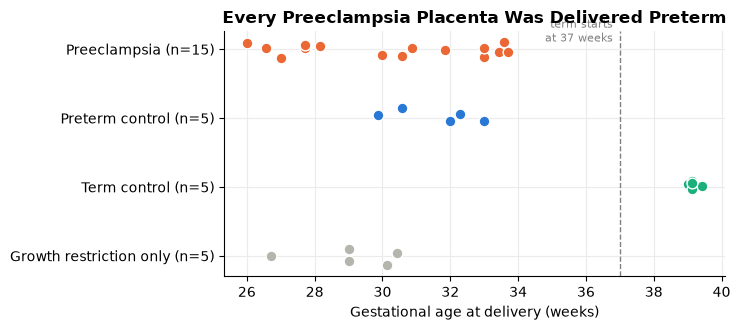

In [3]:
metadata["q6_group"] = np.select(
    [metadata["pe_status"] == "PE", metadata["control_type"] == "preterm_birth", metadata["control_type"] == "term_birth"],
    ["PE", "preterm_control", "term_control"], default="FGR_only")
GROUP_ORDER = ["PE", "preterm_control", "term_control", "FGR_only"]

display(metadata.groupby("q6_group")["ga_delivery_weeks"].agg(n="size", earliest="min", average="mean", latest="max")
        .reindex(GROUP_ORDER).round(1))

# Figure 1: when was each placenta delivered?
fig, ax = plt.subplots(figsize=(7.5, 3.4))
jitter = rng.uniform(-0.15, 0.15, len(metadata))
for i, g in enumerate(GROUP_ORDER):
    sel = (metadata["q6_group"] == g).values
    ax.scatter(metadata.loc[sel, "ga_delivery_weeks"], np.full(sel.sum(), i) + jitter[sel], s=60,
               color=COLORS[g], edgecolor="white", zorder=3)
ax.axvline(37, color="gray", ls="--", lw=1)
ax.text(36.8, -0.45, "term starts\nat 37 weeks", fontsize=8, color="gray", ha="right", va="top")
ax.set_yticks(range(4))
ax.set_yticklabels([f"{LABELS[g]} (n={(metadata['q6_group'] == g).sum()})" for g in GROUP_ORDER])
ax.invert_yaxis()
ax.set_xlabel("Gestational age at delivery (weeks)")
ax.set_title("Every Preeclampsia Placenta Was Delivered Preterm")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig1_delivery_timing.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** Preeclampsia placentas were delivered between 26 and 34 weeks (average 30.2). Preterm controls fall in the same window (average 31.5), while term controls sit about 9 weeks later (average 39.2). In a typical study with only term controls, disease and delivery timing would be impossible to separate. The preterm controls are what make our question answerable.

One flagged value matters here: S26's delivery age was published as "38.7" (38 weeks + 7 days). We keep the released value of 39.0 weeks. It is a term control either way.

## 3. Explore the Samples

PCA squeezes each sample's ~16,000 gene measurements into two numbers so we can plot them. Samples close together have similar overall gene activity. We first keep genes with at least 10 reads in at least 5 samples, since almost-silent genes only add noise. We use this same gene list for every test below.

We color the plot two ways: by group, then by delivery week. If timing drove the biggest differences, the delivery-week coloring would show a smooth gradient along the first axis (PC1).

Genes kept: 15,835 of 26,485


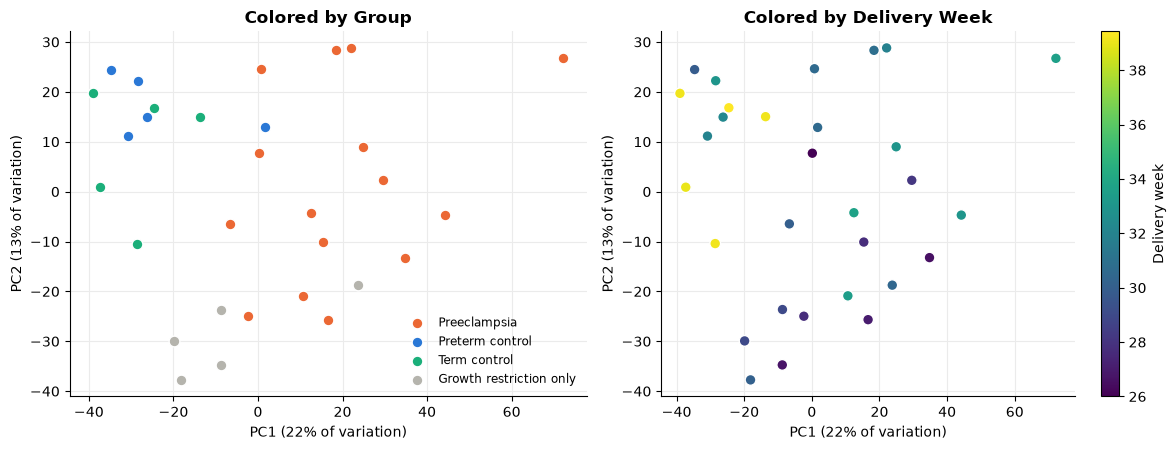

Share of PC1 explained by preeclampsia status: 54%   by delivery week: 12%
Average PC1 position: {'PE': 20.0, 'preterm_control': -24.0, 'term_control': -29.0, 'FGR_only': -6.0}


In [4]:
counts_f = counts.loc[(counts >= 10).sum(axis=1) >= 5]
print(f"Genes kept: {len(counts_f):,} of {len(counts):,}")
log_cpm = np.log2(counts_f.div(counts_f.sum(axis=0), axis=1) * 1e6 + 1)   # depth-adjusted, log scale
pca = PCA(n_components=2)
pcs = pd.DataFrame(pca.fit_transform(log_cpm.T), index=counts_f.columns, columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for g in GROUP_ORDER:
    sel = metadata["q6_group"] == g
    axes[0].scatter(pcs.loc[sel, "PC1"], pcs.loc[sel, "PC2"], s=60, color=COLORS[g], edgecolor="white", label=LABELS[g])
axes[0].legend(fontsize=8.5)
axes[0].set_title("Colored by Group")
pts = axes[1].scatter(pcs["PC1"], pcs["PC2"], c=metadata["ga_delivery_weeks"], cmap="viridis", s=60, edgecolor="white")
fig.colorbar(pts, ax=axes[1], label="Delivery week")
axes[1].set_title("Colored by Delivery Week")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig2_pca.png", dpi=300, bbox_inches="tight")
plt.show()

# How much of PC1 lines up with preeclampsia status vs delivery week? (squared correlation, 0 to 1)
r2_pe = np.corrcoef(pcs["PC1"], metadata["pe_status"] == "PE")[0, 1] ** 2
r2_ga = np.corrcoef(pcs["PC1"], metadata["ga_delivery_weeks"])[0, 1] ** 2
print(f"Share of PC1 explained by preeclampsia status: {r2_pe:.0%}   by delivery week: {r2_ga:.0%}")
print("Average PC1 position:", pcs["PC1"].groupby(metadata["q6_group"]).mean().reindex(GROUP_ORDER).round(0).to_dict())

**What this shows.** The biggest pattern in the data (PC1, the horizontal axis) separates preeclampsia from *both* kinds of control. Preterm and term controls sit together on the left, even though they were delivered 8 weeks apart. Preeclampsia status lines up with 54% of PC1; delivery week lines up with only 12%, and most of that comes from its overlap with preeclampsia. If timing drove PC1, the preterm controls would sit near the cases. They sit near the term controls instead.

One preeclampsia sample (S01) sits far to the right. It lies in the same direction as the other cases, so it looks like an extreme case rather than a broken sample. Its read count (6.8 million) is below the median (11.7 million) but not the lowest in the dataset. Following the workflow guidance, we keep all 30 samples.

## 4. Choose a Comparison

**Our main comparison: preeclampsia (15) vs preterm controls (5).** The two groups were delivered in the same weeks, so delivery timing is removed by design rather than by a statistical correction.

We did not simply add delivery week as a covariate across all controls. The term controls all sit at 39 weeks, far outside the 26 to 34 week range of the cases. The model would have to guess how genes behave across that gap, with no cases there to check it.

The other comparisons we need (PE vs term controls, and preterm vs term controls) come in Section 9. We set all of them before looking at any results.

In [5]:
# Our decisions
GROUP_COLUMN = "q6_group"
CASE = "PE"
CONTROL = "preterm_control"
COVARIATES = []

def build_comparison(counts, metadata):
    used = [GROUP_COLUMN] + list(COVARIATES)
    meta = metadata[metadata[GROUP_COLUMN].isin([CASE, CONTROL])][used].copy()
    n_before = len(meta)
    meta = meta.dropna()
    if len(meta) < n_before:
        print(f"Note: {n_before - len(meta)} sample(s) dropped for missing values in {used}. Report this.")
    print(meta[GROUP_COLUMN].value_counts().to_string())
    return counts[meta.index], meta

comp_counts, comp_meta = build_comparison(counts_f, metadata)

q6_group
PE                 15
preterm_control     5


## 5. Run the Test

PyDESeq2 adjusts for sequencing depth, then asks for every gene: is the difference between the two groups bigger than the normal sample-to-sample variation? We wrap it in two small functions because later sections reuse it with identical settings.

In [6]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

INFERENCE = DefaultInference(n_cpus=os.cpu_count())

def fit_deseq(cnts, meta, design):
    dds = DeseqDataSet(counts=cnts.T.astype(int), metadata=meta, design=design, quiet=True, inference=INFERENCE)
    dds.deseq2()
    return dds

def test_contrast(dds, contrast):
    st = DeseqStats(dds, contrast=contrast, quiet=True, inference=INFERENCE)
    st.summary()
    return st.results_df.sort_values("padj")

design = "~" + " + ".join(list(COVARIATES) + [GROUP_COLUMN])
print("Design:", design)
results = test_contrast(fit_deseq(comp_counts, comp_meta, design), [GROUP_COLUMN, CASE, CONTROL])
results.to_csv(RESULTS_DIR / "de_results.csv")
print(f"Tested {len(results):,} genes. Saved to results/de_results.csv")
display(results.head(10))

Design: ~q6_group


Tested 15,835 genes. Saved to results/de_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
LEPROTL1,741.163767,1.000805,0.088343,11.328648,9.465448e-30,1.440263e-25
NTRK2,256.383815,3.860358,0.454034,8.502359,1.857755e-17,1.413380e-13
AFF3,260.879652,-1.653637,0.198556,-8.328326,8.199368e-17,4.158719e-13
COASY,820.215985,-0.994770,0.122086,-8.148097,3.696948e-16,1.406319e-12
AMD1,3677.103819,1.028512,0.134195,7.664306,1.798014e-14,5.471715e-11
ENG,7529.862816,2.090184,0.286009,7.308097,2.709512e-13,6.871322e-10
FLT1,126519.988711,2.999385,0.415550,7.217875,5.280629e-13,1.147858e-09
CP,162.539974,4.194032,0.582533,7.199642,6.037079e-13,1.148253e-09
HTRA4,9870.028873,2.970925,0.418948,7.091395,1.327666e-12,2.244641e-09


## 6. Read the Results

**Our cutoffs: adjusted p-value below 0.05 and at least a 2-fold change** (`|log2FoldChange| >= 1`).

- `padj < 0.05` is the usual standard. It means we expect about 5% of the genes we call to be false alarms.
- The 2-fold floor keeps effects large enough to matter biologically. With only 5 controls, small changes are the least trustworthy anyway.

The table under the plot shows how the count shifts with stricter or looser cutoffs.

472 genes pass (283 higher in preeclampsia, 189 lower).


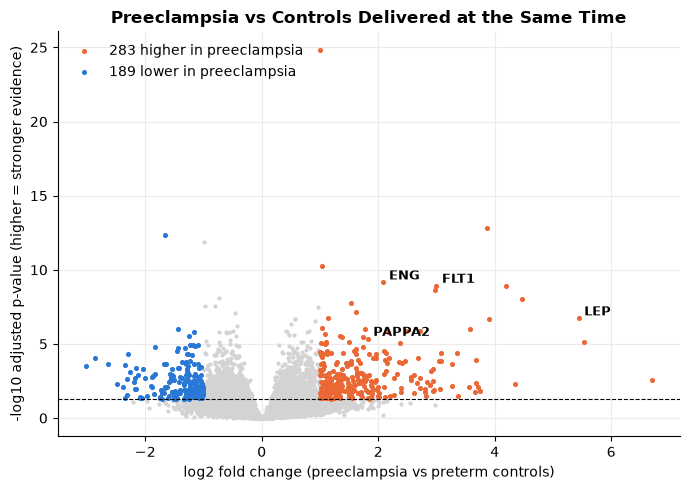

,at least 1.5-fold,at least 2.0-fold,at least 4.0-fold
padj < 0.01,613,293,67
padj < 0.05,1083,472,90
padj < 0.1,1377,564,96


In [7]:
PADJ_CUTOFF = 0.05
LFC_CUTOFF = 1.0

def passing_genes(res, padj=PADJ_CUTOFF, lfc=LFC_CUTOFF):
    return res[(res["padj"] < padj) & (res["log2FoldChange"].abs() >= lfc)]

hits = passing_genes(results)
hits.to_csv(RESULTS_DIR / "passing_genes.csv")
up, down = hits[hits["log2FoldChange"] > 0], hits[hits["log2FoldChange"] < 0]
print(f"{len(hits)} genes pass ({len(up)} higher in preeclampsia, {len(down)} lower).")

fig, ax = plt.subplots(figsize=(7, 5))
nlp = lambda r: -np.log10(r["padj"].clip(lower=1e-300))
ax.scatter(results["log2FoldChange"], nlp(results), s=4, color="lightgray", rasterized=True)
ax.scatter(up["log2FoldChange"], nlp(up), s=7, color=COLORS["PE"], label=f"{len(up)} higher in preeclampsia")
ax.scatter(down["log2FoldChange"], nlp(down), s=7, color=COLORS["preterm_control"], label=f"{len(down)} lower in preeclampsia")
ax.axhline(-np.log10(PADJ_CUTOFF), ls="--", lw=0.8, color="black")
for g in ["FLT1", "LEP", "ENG", "PAPPA2"]:
    ax.annotate(g, (results.loc[g, "log2FoldChange"], nlp(results.loc[[g]]).iloc[0]), fontsize=9, fontweight="bold",
                xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("log2 fold change (preeclampsia vs preterm controls)")
ax.set_ylabel("-log10 adjusted p-value (higher = stronger evidence)")
ax.set_title("Preeclampsia vs Controls Delivered at the Same Time")
ax.legend(loc="upper left")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "volcano.png", dpi=300, bbox_inches="tight")
plt.show()

display(pd.DataFrame({f"at least {2**l:.1f}-fold": {f"padj < {p}": len(passing_genes(results, p, l)) for p in (0.01, 0.05, 0.1)}
                      for l in (0.58, 1, 2)}))

**What this shows.** Against controls delivered in the same weeks, 472 genes differ at least 2-fold. Most of them (283) are *higher* in preeclampsia. Several of the best-known preeclampsia genes are among the strongest hits:

- **FLT1** makes sFlt-1, a protein that blocks blood-vessel growth. Its blood level is part of a clinical test for preeclampsia.
- **ENG** (endoglin) makes another vessel-blocking protein.
- **LEP** (leptin) and **PAPPA2** are hormones known to be raised in preeclamptic placentas.

The gene count moves smoothly as the cutoffs change, so our story does not hinge on one particular threshold.

## 7. Connect Genes to Cell Types

Bulk tissue mixes many cell types. A marker is a gene used mostly by one cell type, so if several markers of one type move together, the tissue may simply contain more or less of that cell type. Here we check which of our passing genes are markers.

In [8]:
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
overlap = markers.merge(hits[["log2FoldChange", "padj"]], left_on="gene_symbol", right_index=True)
display(overlap.sort_values(["cell_class", "log2FoldChange"]) if not overlap.empty else "No passing genes are markers.")

,cell_class,compartment,gene_symbol,log2FoldChange,padj
13,decidual_nk_cell,maternal,KIT,1.778870,9.373005e-07
4,syncytiotrophoblast,fetal,CGA,1.168622,1.358349e-02


Next we looked up five genes in the [Zeisel/Admati gene browser](https://storage.googleapis.com/www_zeisellab/PE_web/pe_web_test_v1.html), a single-cell map of placentas from a different preeclampsia study. We picked genes that tell our story, not just the top of the list:

- **FLT1, ENG, PAPPA2, LEP:** well measured, and higher in preeclampsia against *both* control groups.
- **HLA-G:** looks higher in preeclampsia only when compared with term controls (Section 11).

The browser has no legend for its significance stars. We read red stars as "higher in preeclampsia," which matches the well-known direction of FLT1 and LEP. Browser images are supporting context from other patients, not proof. These annotations are qualitative and cannot distinguish cell-intrinsic expression changes from changes in cell mixture. In particular, the supplied FLT1 note that its rise is "inside cells" is an interpretation, not a conclusion established by the browser alone. Do not treat these lookups as independent validation.


In [9]:
browser_lookups = pd.read_csv(Path("inputs/track01_browser_lookups.csv"))
required_columns = {"gene", "cell_types_expressing", "specificity", "differs_PE_vs_control", "notes"}
missing_columns = required_columns - set(browser_lookups.columns)
if missing_columns:
    raise ValueError(f"Browser lookup file is missing required columns: {sorted(missing_columns)}")
if len(browser_lookups) < 3:
    raise ValueError(f"Browser lookup file must contain at least three rows; found {len(browser_lookups)}")
blank_genes = browser_lookups["gene"].isna() | browser_lookups["gene"].astype(str).str.strip().eq("")
if blank_genes.any():
    raise ValueError("Browser lookup file contains blank gene symbols")
if browser_lookups["gene"].duplicated().any():
    raise ValueError("Browser lookup file contains duplicate gene symbols")

browser_lookups.to_csv(RESULTS_DIR / "browser_lookups.csv", index=False)
display(browser_lookups)


,gene,cell_types_expressing,specificity,differs_PE_vs_control,notes
0,FLT1,"Extravillous trophoblast (highest), other trop...",a few types,Higher in PE in most trophoblast and vascular ...,Agrees with our bulk result; the rise is seen ...
1,ENG,"Endothelial cells (highest), macrophages, some...",broad,Higher in PE in many clusters,Too widespread to pin to one cell type from bu...
2,PAPPA2,"Extravillous trophoblast, some syncytiotrophob...",trophoblast only,Higher in PE in many trophoblast clusters,A trophoblast gene that rises in PE against ei...
3,LEP,Syncytiotrophoblast (sparse),one type,Higher in PE in several trophoblast clusters,Syncytiotrophoblast is poorly captured by sing...
4,HLA-G,Extravillous trophoblast only,one type,"Mixed (some clusters up, one down)",Classic marker of extravillous trophoblast; it...


## 8. Optional: Single-Cell Extension

We did not use the pseudobulk files. In the single-cell data, the early-onset comparison has only 3 control donors, too few to measure a timing effect reliably. A cell-type-by-cell-type timing comparison is listed as a next step at the end of the notebook.

---
# Answering Question 6

## 9. Same Disease, Different Controls

If delivery timing were behind the preeclampsia signal, we would expect:

1. **PE vs term controls** (about 9 weeks apart) to show many more differences than **PE vs preterm controls** (same weeks). Both comparisons use 15 cases and 5 controls, so the comparison is fair.
2. **Preterm vs term controls** (no disease, 8 weeks apart) to show many differences of their own.

We fit one model with all three groups, so the three comparisons share the same estimates of noise. We also run the "naive" comparison many studies would start with: PE vs all 10 controls pooled.

In [10]:
cmp_meta = metadata.loc[metadata["q6_group"] != "FGR_only", ["q6_group", "fgr_status", "fetal_sex"]].copy()
cmp_meta["pe_vs_control"] = np.where(cmp_meta["q6_group"] == "PE", "PE", "control")
cmp_counts = counts_f[cmp_meta.index]

dds3 = fit_deseq(cmp_counts, cmp_meta, "~q6_group")
res = {
    "PE vs all controls (naive)": test_contrast(fit_deseq(cmp_counts, cmp_meta, "~pe_vs_control"), ["pe_vs_control", "PE", "control"]),
    "PE vs term controls": test_contrast(dds3, ["q6_group", "PE", "term_control"]),
    "PE vs preterm controls": test_contrast(dds3, ["q6_group", "PE", "preterm_control"]),
    "Preterm vs term controls": test_contrast(dds3, ["q6_group", "preterm_control", "term_control"]),
}
for name, r in res.items():
    r.to_csv(RESULTS_DIR / f"de_{name.split(' (')[0].replace(' ', '_')}.csv")

de_counts = pd.DataFrame({
    "samples": ["15 vs 10", "15 vs 5", "15 vs 5", "5 vs 5"],
    "genes passing": [len(passing_genes(r)) for r in res.values()],
}, index=res.keys())
de_counts.to_csv(RESULTS_DIR / "de_counts_by_comparison.csv")
display(de_counts)

,samples,genes passing
PE vs all controls (naive),15 vs 10,582
PE vs term controls,15 vs 5,532
PE vs preterm controls,15 vs 5,532
Preterm vs term controls,5 vs 5,11


**What this shows.** At this threshold, the PE comparisons yield 532 passing genes with either term or same-time preterm controls. Equal counts do not mean the gene lists or effect sizes are identical. The two control groups, delivered 8 weeks apart, differ in **11** genes; the naive pooled comparison finds 582.

Both expectations from above fail. That points to timing being a small part of the preeclampsia signal. But a 5-vs-5 test is small, so Section 10 checks whether we simply lacked the power to see timing effects.

## 10. Is That Just Because 5 vs 5 Is a Small Test?

With only 5 samples per group, a test can miss real differences. To check, we ran two other comparisons of exactly the same size, 8 times each:

- **5 random preeclampsia cases vs the 5 preterm controls.** This shows how many genes a real disease difference produces at this sample size.
- **The 10 controls split into two random groups of 5.** No real difference exists here, so this shows how many genes pure noise produces.

If timing mattered as much as preeclampsia, the real preterm-vs-term result would look like the first set. If timing barely mattered, it would look like the second.

5 PE vs 5 preterm controls: [312, 420, 494, 567, 577, 602, 714, 739]
Random split of controls:   [0, 2, 2, 5, 5, 6, 6, 10]
Preterm vs term controls:   11


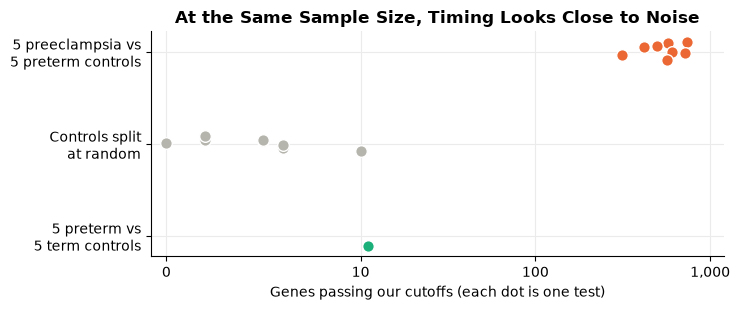

In [11]:
N_DRAWS = 8
pe_ids = cmp_meta.index[cmp_meta["q6_group"] == "PE"].tolist()
pre_ids = cmp_meta.index[cmp_meta["q6_group"] == "preterm_control"].tolist()
term_ids = cmp_meta.index[cmp_meta["q6_group"] == "term_control"].tolist()

def n_genes_5v5(a_ids, b_ids):
    m = pd.DataFrame({"grp": ["A"] * 5 + ["B"] * 5}, index=list(a_ids) + list(b_ids))
    return len(passing_genes(test_contrast(fit_deseq(counts_f[m.index], m, "~grp"), ["grp", "A", "B"])))

disease_draws, noise_draws = [], []
for _ in range(N_DRAWS):
    disease_draws.append(n_genes_5v5(rng.choice(pe_ids, 5, replace=False), pre_ids))
    split = list(rng.permutation(pre_ids + term_ids))
    while set(split[:5]) in (set(pre_ids), set(term_ids)):      # skip the real split
        split = list(rng.permutation(pre_ids + term_ids))
    noise_draws.append(n_genes_5v5(split[:5], split[5:]))
timing_actual = len(passing_genes(res["Preterm vs term controls"]))
pd.DataFrame({"disease_5v5": disease_draws, "noise_5v5": noise_draws}).to_csv(RESULTS_DIR / "power_check.csv", index=False)
print("5 PE vs 5 preterm controls:", sorted(disease_draws))
print("Random split of controls:  ", sorted(noise_draws))
print("Preterm vs term controls:  ", timing_actual)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
rows = [("5 preeclampsia vs\n5 preterm controls", disease_draws, COLORS["PE"]),
        ("Controls split\nat random", noise_draws, "#b5b4ad"),
        ("5 preterm vs\n5 term controls", [timing_actual], COLORS["term_control"])]
for i, (lab, vals, c) in enumerate(rows):
    ax.scatter(vals, i + rng.uniform(-0.12, 0.12, len(vals)), s=70, color=c, edgecolor="white", zorder=3)
ax.set_yticks(range(3)); ax.set_yticklabels([r[0] for r in rows]); ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(-0.8, 1200)
ax.set_xticks([0, 10, 100, 1000]); ax.set_xticklabels(["0", "10", "100", "1,000"])
ax.set_xlabel("Genes passing our cutoffs (each dot is one test)")
ax.set_title("At the Same Sample Size, Timing Looks Close to Noise")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig3_power_check.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** Five preeclampsia cases against five preterm controls still produce 312 to 739 genes, so a 5-vs-5 test *can* detect a real biological difference. Random splits of the controls produce 0 to 10 genes. The real preterm-vs-term comparison gives 11, just above that noise range and about 50 times smaller than the disease effect at the same sample size.

So the small timing effect is not just a power problem. Eight weeks of extra pregnancy, without preeclampsia, changes far fewer genes than preeclampsia does.

## 11. Putting a Number on It

Take every gene that passes for **PE vs term controls**, the comparison most exposed to timing. On the log scale, its difference splits exactly into two parts:

> (PE vs term) = (PE vs preterm) **+** (preterm vs term)
>
> total difference = **disease part** (same delivery weeks) + **timing part** (controls only)

For each gene we ask which part carries it:

- **Holds up against same-time controls:** still significant against preterm controls, in the same direction.
- **Explained by timing:** no longer significant against preterm controls, and the timing part makes up at least half of the original difference.
- **Unclear:** neither; the data are too noisy to say.

532 genes differ between preeclampsia and term controls. Of these:
   53%  Holds up against same-time controls
   18%  Unclear
   28%  Explained by timing

For the typical gene, the timing part is 30% of the total difference.

Best-measured genes explained by timing:


,total,disease,timing,baseMean
gene,,,,
FN1,2.17,0.74,1.43,126833.35
PSG2,1.00,0.31,0.70,31776.41
TIMP3,1.39,0.39,1.00,17349.15
PRG2,3.00,0.41,2.59,16295.87
SERPINE1,1.36,0.60,0.75,9081.41
AOC1,1.90,0.74,1.16,8627.70
ISM2,1.17,0.13,1.04,4303.37
MUC15,-1.16,-0.49,-0.67,2163.27


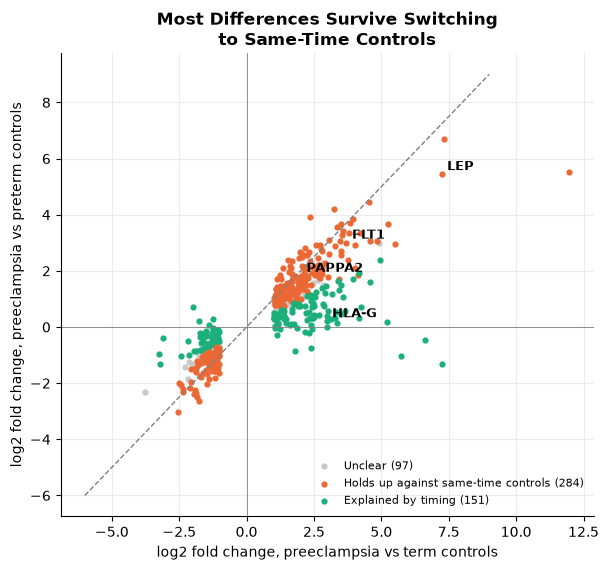

In [12]:
lfc = pd.DataFrame({k: res[k]["log2FoldChange"] for k in ["PE vs term controls", "PE vs preterm controls", "Preterm vs term controls"]})
lfc.columns = ["total", "disease", "timing"]
padj_disease = res["PE vs preterm controls"]["padj"]

term_hits = passing_genes(res["PE vs term controls"]).index
holds = (padj_disease < PADJ_CUTOFF) & (np.sign(lfc["disease"]) == np.sign(lfc["total"]))
timing_share = lfc["timing"] / lfc["total"]
category = pd.Series("Unclear", index=term_hits)
category[holds[term_hits]] = "Holds up against same-time controls"
category[(~holds & (timing_share >= 0.5))[term_hits]] = "Explained by timing"
share = category.value_counts(normalize=True)

print(f"{len(term_hits)} genes differ between preeclampsia and term controls. Of these:")
for c in ["Holds up against same-time controls", "Unclear", "Explained by timing"]:
    print(f"  {share.get(c, 0):4.0%}  {c}")
print(f"\nFor the typical gene, the timing part is {timing_share[term_hits].median():.0%} of the total difference.")
category.rename("category").to_frame().join(lfc).to_csv(RESULTS_DIR / "pe_vs_term_genes_classified.csv")
print("\nBest-measured genes explained by timing:")
display(lfc.loc[category.index[category == "Explained by timing"]]
        .join(res["PE vs term controls"]["baseMean"]).sort_values("baseMean", ascending=False).head(8).round(2))

# Figure: each gene's difference against term controls (x) and against same-time controls (y)
cat_colors = {"Holds up against same-time controls": COLORS["PE"], "Unclear": "#c8c8c8", "Explained by timing": COLORS["term_control"]}
fig, ax = plt.subplots(figsize=(6.2, 5.8))
for c in ["Unclear", "Holds up against same-time controls", "Explained by timing"]:
    g = category.index[category == c]
    ax.scatter(lfc.loc[g, "total"], lfc.loc[g, "disease"], s=12, color=cat_colors[c], label=f"{c} ({len(g)})")
ax.plot([-6, 9], [-6, 9], color="gray", ls="--", lw=1)
ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
for g in ["FLT1", "LEP", "PAPPA2", "HLA-G"]:
    ax.annotate(g, (lfc.loc[g, "total"], lfc.loc[g, "disease"]), fontsize=9, fontweight="bold", xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("log2 fold change, preeclampsia vs term controls")
ax.set_ylabel("log2 fold change, preeclampsia vs preterm controls")
ax.set_title("Most Differences Survive Switching\nto Same-Time Controls")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig4_term_vs_preterm_fold_changes.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** Of the 532 genes that differ between preeclampsia and term controls:

- **About half (52%) hold up** against controls delivered in the same weeks. These include FLT1, LEP and PAPPA2, which sit close to the dashed line in the plot, meaning they show the same size of difference against either control group.
- **About a quarter (28%) look explained by timing.** These are the green points that fall toward zero when same-time controls are used. HLA-G, FN1, TIMP3, SERPINE1 and PRG2 are examples.
- **The rest (19%) are unclear.**

For the typical gene, timing accounts for about **30%** of its difference from term controls.

How does this fit with only 11 significant timing genes in Section 9? Timing effects are real but small, so few of them reach significance on their own. They become visible only when they add to a preeclampsia difference that is already there. Several of the timing genes (HLA-G, PRG2) belong to extravillous trophoblast, the cells that anchor the placenta into the uterine wall. Our speculation: preterm and term placenta samples may contain different amounts of that tissue.

## 12. Seeing It Sample by Sample

Two genes show the two patterns. Each dot is one placenta, plotted by delivery week.

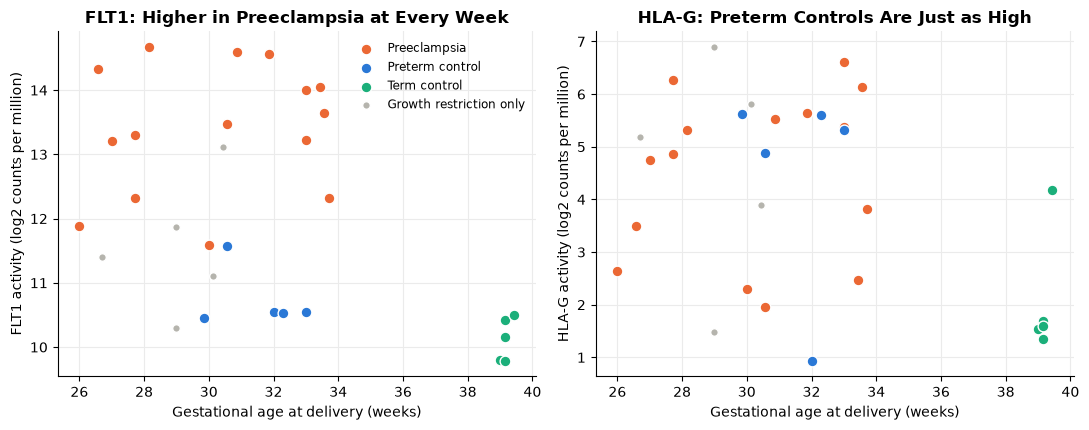

In [13]:
def gene_vs_week(ax, gene, legend=False):
    for g in GROUP_ORDER:
        sel = metadata["q6_group"] == g
        ax.scatter(metadata.loc[sel, "ga_delivery_weeks"], log_cpm.loc[gene, sel], s=60 if g != "FGR_only" else 30,
                   color=COLORS[g], edgecolor="white", label=LABELS[g], zorder=3 if g != "FGR_only" else 2)
    ax.set_xlabel("Gestational age at delivery (weeks)")
    ax.set_ylabel(f"{gene} activity (log2 counts per million)")
    if legend:
        ax.legend(fontsize=8.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
gene_vs_week(axes[0], "FLT1", legend=True)
axes[0].set_title("FLT1: Higher in Preeclampsia at Every Week")
gene_vs_week(axes[1], "HLA-G")
axes[1].set_title("HLA-G: Preterm Controls Are Just as High")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig5_genes_by_delivery_week.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** FLT1 is high in almost every preeclampsia placenta, whether delivered at 26 or 34 weeks. Controls are low whether delivered at 30 or 39 weeks. HLA-G looks raised in preeclampsia only if you compare against term controls. Preterm controls are just as high, so the apparent difference comes from timing (or the tissue mix at term), not from the disease. In the gene browser, HLA-G is found only in extravillous trophoblast.

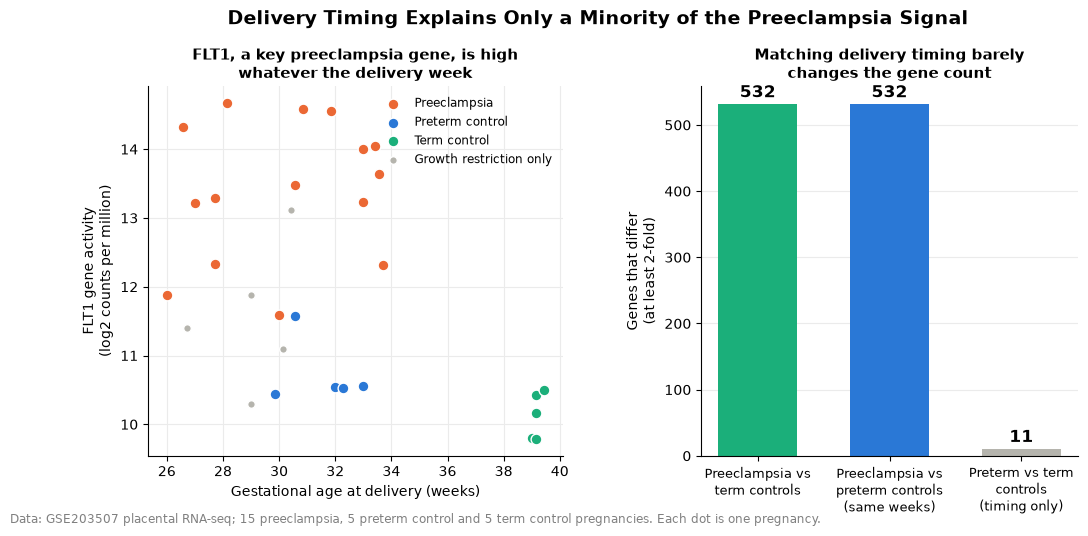

In [14]:
# Headline visual for a general audience
n_term, n_pre, n_time = (len(passing_genes(res[k])) for k in ["PE vs term controls", "PE vs preterm controls", "Preterm vs term controls"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.35})
gene_vs_week(axes[0], "FLT1", legend=True)
axes[0].set_ylabel("FLT1 gene activity\n(log2 counts per million)")
axes[0].set_title("FLT1, a key preeclampsia gene, is high\nwhatever the delivery week", fontsize=11)
bars = [("Preeclampsia vs\nterm controls", n_term, COLORS["term_control"]),
        ("Preeclampsia vs\npreterm controls\n(same weeks)", n_pre, COLORS["preterm_control"]),
        ("Preterm vs term\ncontrols\n(timing only)", n_time, "#b5b4ad")]
for i, (lab, v, c) in enumerate(bars):
    axes[1].bar(i, v, color=c, width=0.6)
    axes[1].text(i, v + 10, str(v), ha="center", fontsize=12, fontweight="bold")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels([b[0] for b in bars], fontsize=9.5)
axes[1].set_ylabel("Genes that differ\n(at least 2-fold)")
axes[1].grid(axis="x", visible=False)
axes[1].set_title("Matching delivery timing barely\nchanges the gene count", fontsize=11)
fig.suptitle("Delivery Timing Explains Only a Minority of the Preeclampsia Signal", fontsize=14, fontweight="bold", y=1.04)
fig.text(0.01, -0.03, "Data: GSE203507 placental RNA-seq; 15 preeclampsia, 5 preterm control and 5 term control pregnancies. "
         "Each dot is one pregnancy.", fontsize=8.5, color="gray")
plt.savefig(RESULTS_DIR / "headline.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Robustness Checks

We reran the main comparison (PE vs preterm controls) three ways. Each targets something other than timing that differs between the groups:

- **Growth restriction:** 7 of the 15 cases also have growth restriction (FGR), and no preterm control does. We add `fgr_status` as a covariate.
- **Fetal sex:** placental gene activity differs by the baby's sex. We add `fetal_sex` as a covariate.
- **Remaining timing gap:** cases were delivered about 1.3 weeks earlier than preterm controls on average. We add delivery week as a covariate.

For each, we ask what share of our main genes still pass in the same direction.

In [15]:
main = res["PE vs preterm controls"]
main_hits = passing_genes(main).index
pt = metadata.loc[pe_ids + pre_ids, ["q6_group", "fgr_status", "fetal_sex", "ga_delivery_weeks"]]
rows = {}
for name, design in [("+ growth restriction", "~fgr_status + q6_group"), ("+ fetal sex", "~fetal_sex + q6_group"),
                     ("+ delivery week", "~ga_delivery_weeks + q6_group")]:
    r = test_contrast(fit_deseq(counts_f[pt.index], pt, design), ["q6_group", "PE", "preterm_control"])
    same = (r.loc[main_hits, "padj"] < PADJ_CUTOFF) & (np.sign(r.loc[main_hits, "log2FoldChange"]) == np.sign(main.loc[main_hits, "log2FoldChange"]))
    rows[name] = {"genes passing": len(passing_genes(r)), "main genes still significant, same direction": f"{same.mean():.0%}",
                  "fold-change agreement (correlation)": round(r.loc[main_hits, "log2FoldChange"].corr(main.loc[main_hits, "log2FoldChange"]), 2)}
robust = pd.DataFrame(rows).T
robust.to_csv(RESULTS_DIR / "robustness_checks.csv")
print(f"Main comparison: {len(main_hits)} genes")
display(robust)

Main comparison: 532 genes


,genes passing,"main genes still significant, same direction",fold-change agreement (correlation)
+ growth restriction,293,52%,0.99
+ fetal sex,426,76%,1.0
+ delivery week,529,86%,0.99


**What this shows.** Our main result holds up. In every check the fold changes agree almost perfectly with the main analysis (correlation 0.99 to 1.0), so the *size and direction* of the differences do not depend on these factors.

- Adjusting for the remaining 1.3-week timing gap keeps 87% of the main genes significant. This is one more sign that timing matters little.
- Adjusting for fetal sex keeps 78%.
- Adjusting for growth restriction keeps only 53%. That is mostly lost power, not lost signal: growth restriction occurs only within the preeclampsia group here, so the model must estimate the preeclampsia effect from the 8 cases without it. The effect sizes stay the same (correlation 0.99).

---
## Our Answer

**Delivery timing explains only a minority of the difference between early-onset preeclampsia and control placentas in this dataset.**

- The PE-vs-term and PE-vs-preterm contrasts each yield 532 passing genes in this rerun. Equal counts do not establish identical gene lists or effect sizes.
- Control placentas delivered 8 weeks apart differ in only 11 genes, close to what random noise produces.
- About half of the differences against term controls hold up against same-time controls. About a quarter look driven by timing. For the typical gene, timing accounts for about 30% of the difference.
- Core preeclampsia genes (FLT1, ENG, LEP, PAPPA2) are raised regardless of when delivery happened.

**Limitations.**

- Our preterm controls are spontaneous preterm births, which often involve inflammation. They are the best comparison available, since healthy pregnancies are not delivered early, but they are not a healthy 31-week placenta.
- There are only 5 controls of each type.
- Bulk tissue mixes many cell types, so we cannot tell whether genes change inside cells or because the cell mix changes.
- All cases are early onset, so the answer may differ for late-onset preeclampsia.
- All of this is association, not cause.

**Next steps.**

- Repeat the timing comparison inside single cell types, using the pseudobulk extension (early vs late control donors).
- Check FLT1, ENG, LEP and PAPPA2 against preterm controls in an independent cohort whose preterm deliveries were medically indicated rather than spontaneous.

Go to [Step 4: Submit](../4-submit.md).